Limiar automático calculado pelo Otsu: 76.0
Sucesso! 6 objetos foram salvos na pasta 'rois_detectadas'.


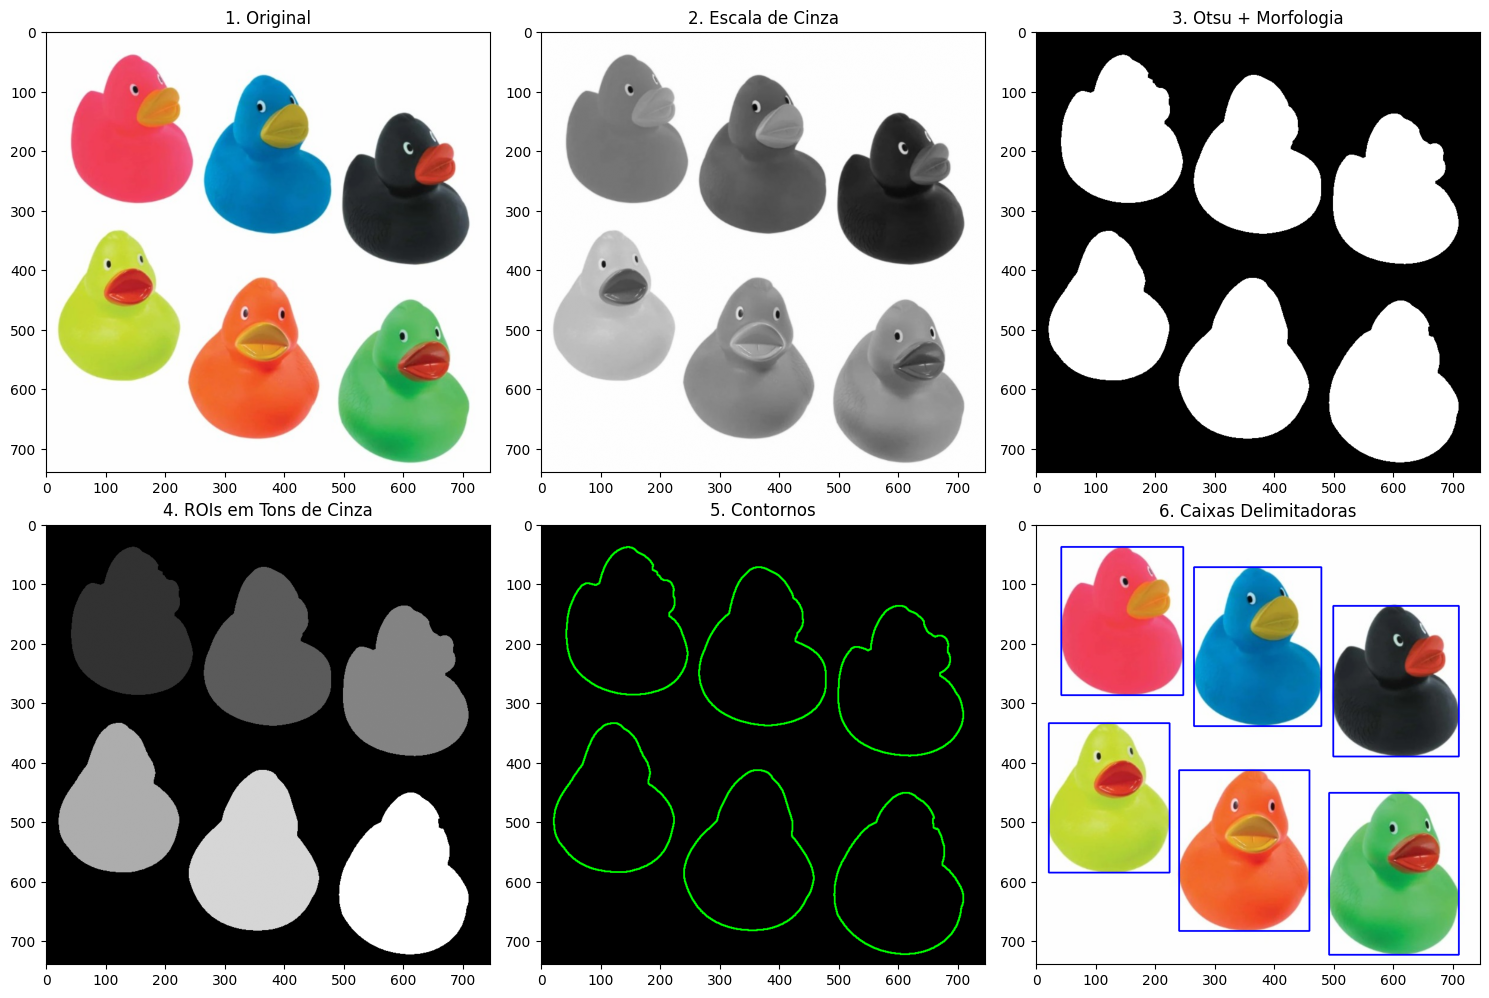

In [ ]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

pasta_de_saida = 'rois_detectadas'
os.makedirs(pasta_de_saida, exist_ok=True)

caminho_da_imagem = 'imagem.jpg'
imagem_original = cv2.imread(caminho_da_imagem)

if imagem_original is None:
    print(f"Erro: Não foi possível carregar '{caminho_da_imagem}'. Verifique o arquivo.")
else:

    imagem_tons_de_cinza = cv2.cvtColor(imagem_original, cv2.COLOR_BGR2GRAY)
    imagem_espaco_hsv = cv2.cvtColor(imagem_original, cv2.COLOR_BGR2HSV)

    canal_de_saturacao = imagem_espaco_hsv[:, :, 1]

    imagem_cinza_invertida = cv2.subtract(255, imagem_tons_de_cinza)

    imagem_combinada = cv2.addWeighted(imagem_cinza_invertida, 0.5, canal_de_saturacao, 0.5, 0)

    imagem_suavizada = cv2.GaussianBlur(imagem_combinada, (5, 5), 0)

    modo_binario = cv2.THRESH_BINARY
    metodo_otsu = cv2.THRESH_OTSU
    configuracao_binarizacao = modo_binario + metodo_otsu

    resultado_threshold = cv2.threshold(imagem_suavizada, 0, 255, configuracao_binarizacao)
    valor_limiar_calculado = resultado_threshold[0]
    imagem_binaria_otsu = resultado_threshold[1]

    print(f"Limiar automático calculado pelo Otsu: {valor_limiar_calculado}")

    elemento_estruturante = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    imagem_morfologica = cv2.morphologyEx(imagem_binaria_otsu, cv2.MORPH_OPEN, elemento_estruturante, iterations=1)
    imagem_morfologica = cv2.morphologyEx(imagem_morfologica, cv2.MORPH_CLOSE, elemento_estruturante, iterations=2)

    quantidade_de_rotulos, matriz_de_rotulos, estatisticas_componentes, centroides_componentes = cv2.connectedComponentsWithStats(imagem_morfologica)

    imagem_rois_tons_cinza = np.zeros_like(imagem_tons_de_cinza, dtype=np.uint8)
    if quantidade_de_rotulos > 1:
        tonalidades_de_cinza = np.linspace(50, 255, quantidade_de_rotulos - 1, dtype=np.uint8)
        for indice in range(1, quantidade_de_rotulos):
            imagem_rois_tons_cinza[matriz_de_rotulos == indice] = tonalidades_de_cinza[indice - 1]

    lista_de_contornos, hierarquia = cv2.findContours(imagem_morfologica, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    imagem_desenho_contornos = np.zeros_like(imagem_original)
    cv2.drawContours(imagem_desenho_contornos, lista_de_contornos, -1, (0, 255, 0), 2)

    imagem_com_caixas_delimitadoras = imagem_original.copy()
    contador_de_rois = 0

    for contorno in lista_de_contornos:
        area_do_contorno = cv2.contourArea(contorno)
        if area_do_contorno > 800:
            contador_de_rois += 1
            posicao_x, posicao_y, largura, altura = cv2.boundingRect(contorno)
            recorte_da_roi = imagem_original[posicao_y:posicao_y + altura, posicao_x:posicao_x + largura]

            caminho_salvamento_roi = os.path.join(pasta_de_saida, f'roi_{contador_de_rois}.png')
            cv2.imwrite(caminho_salvamento_roi, recorte_da_roi)

            cv2.rectangle(imagem_com_caixas_delimitadoras, (posicao_x, posicao_y), (posicao_x + largura, posicao_y + altura), (255, 0, 0), 2)

    print(f"Sucesso! {contador_de_rois} objetos foram salvos na pasta '{pasta_de_saida}'.")

    plt.figure(figsize=(15, 10))
    plt.subplot(2, 3, 1); plt.imshow(cv2.cvtColor(imagem_original, cv2.COLOR_BGR2RGB)); plt.title("1. Original")
    plt.subplot(2, 3, 2); plt.imshow(imagem_tons_de_cinza, cmap='gray'); plt.title("2. Escala de Cinza")
    plt.subplot(2, 3, 3); plt.imshow(imagem_morfologica, cmap='gray'); plt.title("3. Otsu + Morfologia")
    plt.subplot(2, 3, 4); plt.imshow(imagem_rois_tons_cinza, cmap='gray'); plt.title("4. ROIs em Tons de Cinza")
    plt.subplot(2, 3, 5); plt.imshow(cv2.cvtColor(imagem_desenho_contornos, cv2.COLOR_BGR2RGB)); plt.title("5. Contornos")
    plt.subplot(2, 3, 6); plt.imshow(cv2.cvtColor(imagem_com_caixas_delimitadoras, cv2.COLOR_BGR2RGB)); plt.title("6. Caixas Delimitadoras")

    plt.tight_layout()
    plt.show()